# 🌍 Ujian Tengah Semester (UTS) - Penambangan Data Sains (PSD)
## Klasifikasi Penggunaan dan Tutupan Lahan (*Land Use / Land Cover*) Jawa Timur
### Citra Satelit Sentinel-2A + Algoritma Random Forest + Visualisasi Folium (Google Satellite)

* **Nama:** Zaidan Nabil
* **Mata Kuliah:** Penambangan Data Sains (*Data Mining*)
* **Proyek:** Klasifikasi Spasial Tutupan Lahan Berbasis Piksel (*Pixel-Based Classification*)

---

### **Daftar Isi Alur Kerja:**
1. **Data Understanding:** Tujuan analisis, acuan SNI 7645-1:2014, wilayah studi, band Sentinel-2A, serta bukti paradigma *Pixel-based* vs Poligon ROI.
2. **Data Collection:** Persiapan lingkungan, pembacaan shapefile, penentuan sampel, ekstraksi citra Copernicus, dan pemuatan dataset.
3. **Deskripsi Fitur dan Rumusnya:** 10 band reflektansi asli dan 8 indeks spektral turunan (NDVI, NDWI, MNDWI, NDBI, NDRE, EVI, SAVI, BSI).
4. **Eksplorasi Data (EDA):** Distribusi kelas, statistik deskriptif, *Spectral Signature*, sebaran indeks spektral (*boxplot*), dan matriks korelasi.
5. **Pemodelan Random Forest dan Evaluasi:** Data splitting (80:20), pelatihan model, *accuracy score*, *classification report*, dan *confusion matrix*.
6. **Eksperimen Konfigurasi & Hyperparameter:** Eksperimen rasio train-test, kombinasi subset fitur spektral, serta *Grid Search CV*.
7. **Peta Hasil Klasifikasi (Folium):** Peta interaktif klasifikasi semua kelas, peta khusus kelas laut, dan peta area studi (AOI).
8. **Kesimpulan:** Rangkuman performa model dan temuan spektral.

## 1. Data Understanding

### 1.1 Tujuan Analisis Land Use and Land Classification
1. **Mengklasifikasikan** tutupan/penggunaan lahan di wilayah Jawa Timur ke dalam 6 kelas (Sawah, Bangunan, Mangrove, Lahan Hijau, Perairan Terbuka/Laut, Danau) berdasarkan nilai reflektansi band Sentinel-2A dan indeks spektralnya.
2. **Memahami karakteristik spektral** tiap kelas lahan, yaitu band dan indeks mana yang paling membedakan satu kelas dari kelas lain.
3. **Membangun dan mengevaluasi model Random Forest** yang dinilai memiliki akurasi tinggi dan tahan terhadap noise/non-linearitas data spasial multispektral.
4. **Menyajikan peta hasil klasifikasi interaktif** menggunakan WMS satelit Google Maps melalui integrasi pustaka *Folium*.

### 1.2 Acuan Klasifikasi Lahan di Indonesia (SNI 7645-1:2014)
Acuan standar klasifikasi lahan di Indonesia diatur dalam **SNI 7645-1:2014** tentang *Klasifikasi Penutup Lahan*. Standar ini mengelompokkan penutup lahan menjadi hierarki yang memisahkan daerah bervegetasi, perairan (alami dan buatan), serta lahan terbangun. 

Eksperimen ini menggunakan 6 kelas yang mengacu pada SNI:
* **Sawah**: Lahan pertanian basah.
* **Bangunan**: Area permukiman, industri, infrastruktur, dan lahan terbangun lainnya.
* **Mangrove**: Ekosistem vegetasi pesisir pantai.
* **Lahan Hijau**: Hutan dan vegetasi darat selain sawah/mangrove.
* **Perairan Terbuka (Laut)**: Wilayah perairan laut pesisir dan lepas pantai.
* **Danau**: Perairan tawar (waduk/danau alami maupun buatan).

### 1.3 Wilayah Studi
Provinsi **Jawa Timur** ($109.99^\circ - 117.13^\circ$ BT dan $-9.29^\circ - -4.62^\circ$ LS), yang memiliki keragaman bentang alam lengkap dari pegunungan, dataran lumbung pangan, hingga kawasan pesisir kepulauan.

### 1.4 Band pada Citra Sentinel-2A
Sentinel-2A membawa sensor MSI (*MultiSpectral Instrument*) dengan 13 band. Band yang digunakan dalam pemodelan:

| Band | Nama | Panjang Gelombang (nm) | Resolusi Spasial | Kegunaan Utama |
|---|---|---|---|---|
| **B2** | Blue | 492 nm | 10 m | Penetrasi air, pembeda tanah/bangunan |
| **B3** | Green | 560 nm | 10 m | Puncak pantulan vegetasi sehat, indeks air |
| **B4** | Red | 665 nm | 10 m | Penyerapan klorofil |
| **B5** | Red Edge 1 | 704 nm | 20 m | Kandungan klorofil, kesehatan kanopi |
| **B6** | Red Edge 2 | 740 nm | 20 m | Struktur daun dan biomassa |
| **B7** | Red Edge 3 | 783 nm | 20 m | Struktur kanopi vegetasi |
| **B8** | NIR | 833 nm | 10 m | Biomassa vegetasi, pemisah daratan vs air |
| **B8A**| Narrow NIR | 865 nm | 20 m | Kadar air tanaman, biofisik |
| **B11**| SWIR 1 | 1614 nm | 20 m | Kelembapan tanah, area terbangun |
| **B12**| SWIR 2 | 2202 nm | 20 m | Geologi, tanah terbuka, area terbangun |

### 1.5 Pendekatan Metodologi: Pixel-Based Classification vs Polygon ROI
Proyek ini mengadopsi pendekatan **Pixel-Based Classification** (berbasis piksel), di mana:
* **Poligon Shapefile (ROI):** Berfungsi murni pada tahap pengumpulan sampel sebagai batas delimitasi *ground truth* di QGIS agar sampel tidak keliru.
* **Unit Analisis ML:** Setiap baris data dalam dataset merupakan **1 piksel (ukuran 10m x 10m)** dengan koordinat `lat`, `lon` serta 18 nilai fitur pantulan spektral yang diproses secara independen oleh Random Forest.

In [10]:
# Verifikasi Struktur Data Berbasis Piksel
import pandas as pd
from IPython.display import display

df_verifikasi = pd.read_csv('dataset_sentinel2_jatim.csv')

print("=== VERIFIKASI DATA BERBASIS PIKSEL ===")
print(f"Total Piksel Sampel (Baris Data)  : {len(df_verifikasi)} piksel")
print(f"Jumlah Fitur Spektral per Piksel  : {df_verifikasi.shape[1] - 5} fitur (10 Band + 8 Indeks)")
print(f"Resolusi Spasial Sensor           : 10 meter x 10 meter (1 piksel = 100 m² = 0.01 hektar)")
print(f"Jumlah Poligon Ground Truth (ROI) : {df_verifikasi['poligon_id'].nunique()} poligon referensi")
print(f"Rata-rata Piksel per Poligon       : {len(df_verifikasi) / df_verifikasi['poligon_id'].nunique():.1f} piksel/poligon")

print("\nContoh Struktur 5 Observasi Piksel Pertama:")
display(df_verifikasi[['kelas', 'poligon_id', 'lon', 'lat', 'B2', 'B4', 'B8', 'NDVI', 'NDWI']].head())

=== VERIFIKASI DATA BERBASIS PIKSEL ===
Total Piksel Sampel (Baris Data)  : 520 piksel
Jumlah Fitur Spektral per Piksel  : 18 fitur (10 Band + 8 Indeks)
Resolusi Spasial Sensor           : 10 meter x 10 meter (1 piksel = 100 m² = 0.01 hektar)
Jumlah Poligon Ground Truth (ROI) : 50 poligon referensi
Rata-rata Piksel per Poligon       : 10.4 piksel/poligon

Contoh Struktur 5 Observasi Piksel Pertama:


,kelas,poligon_id,lon,lat,B2,B4,B8,NDVI,NDWI
0,Sawah,32,112.622245,-7.411021,0.058330,0.084722,0.281238,0.536987,-0.537329
1,Sawah,7,112.695488,-7.969210,0.046087,0.073554,0.243289,0.535705,-0.448632
2,Sawah,39,112.630735,-7.421205,0.026494,0.061274,0.259071,0.617449,-0.578710
3,Sawah,18,112.574725,-7.210692,0.044119,0.057751,0.252548,0.627770,-0.509340
4,Sawah,4,112.608181,-7.432008,0.050377,0.075123,0.270441,0.565217,-0.558101


## 2. Data Collection

Alur pengumpulan data:
$$\text{Poligon ROI (Shapefile 6 Kelas)} \rightarrow \text{Ekstraksi Titik Piksel} \rightarrow \text{Nilai Spektral Sentinel-2A (Copernicus API)} \rightarrow \text{Hitung Indeks} \rightarrow \text{Dataset CSV}$$

### 2.1 Persiapan Lingkungan dan Import Library

In [11]:
import os, math, time, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import folium
from folium import FeatureGroup, LayerControl
from IPython.display import display, Markdown

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_val_score, GridSearchCV
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Seluruh library berhasil dimuat dengan sukses!")

Seluruh library berhasil dimuat dengan sukses!


### 2.2 Rincian Poligon Shapefile & Target Titik Sampel
Sampel titik piksel diekstraksi dari file shapefile QGIS (*QGZ/SHP*) yang telah dikonversi ke sistem koordinat WGS84 (EPSG:4326):

| ID | Kelas Tutupan Lahan | Berkas Shapefile Asal | Jumlah Sampel Piksel |
|:---:|:---|:---|:---:|
| 1 | Sawah | `50 Sawah gqis.qgz` / `sawah.shp` | 100 piksel |
| 2 | Bangunan | `50 Non Sawah gqis.qgz` / `bangunan.shp` | 100 piksel |
| 3 | Mangrove | `Mangrove Zaidan.zip` / `mangrove.shp` | 80 piksel |
| 4 | Lahan Hijau | `Lahan hijau.zip` / `lahan_hijau.shp` | 80 piksel |
| 5 | Perairan Terbuka (Laut) | `laut.zip` / `lautan.shp` | 80 piksel |
| 6 | Danau | `Danau.zip` / `danau.shp` | 80 piksel |
| **Total** | **6 Kelas** | **Jawa Timur** | **520 piksel** |

### 2.3 Memuat Dataset Hasil Ekstraksi Citra

In [12]:
# Memuat dataset Sentinel-2A Jawa Timur
df = pd.read_csv('dataset_sentinel2_jatim.csv')

print(f"Dataset berhasil dimuat! Dimensi data: {df.shape[0]} baris x {df.shape[1]} kolom.")
display(df.head())

Dataset berhasil dimuat! Dimensi data: 520 baris x 23 kolom.


,kelas_id,kelas,poligon_id,lon,lat,B2,B3,B4,B5,B6,...,B11,B12,NDVI,NDWI,MNDWI,NDBI,NDRE,EVI,SAVI,BSI
0,1,Sawah,32,112.622245,-7.411021,0.058330,0.084641,0.084722,0.112528,0.260131,...,0.196046,0.142746,0.536987,-0.537329,-0.396902,-0.178494,0.428454,0.363355,0.340401,-0.094788
1,1,Sawah,7,112.695488,-7.969210,0.046087,0.092599,0.073554,0.128426,0.250458,...,0.218268,0.125933,0.535705,-0.448632,-0.404254,-0.054210,0.309009,0.316914,0.311690,0.004210
2,1,Sawah,39,112.630735,-7.421205,0.026494,0.069135,0.061274,0.124518,0.209361,...,0.222137,0.117813,0.617449,-0.578710,-0.525290,-0.076753,0.350774,0.346280,0.361671,-0.003786
3,1,Sawah,18,112.574725,-7.210692,0.044119,0.082099,0.057751,0.112798,0.215897,...,0.220946,0.096194,0.627770,-0.509340,-0.458173,-0.066743,0.382516,0.384014,0.360601,-0.031233
4,1,Sawah,4,112.608181,-7.432008,0.050377,0.076701,0.075123,0.129806,0.208196,...,0.176787,0.125186,0.565217,-0.558101,-0.394836,-0.209410,0.351371,0.363492,0.346488,-0.120316


## 3. Deskripsi Fitur dan Rumusnya

Selain 10 band spektral asli, diekstraksi **8 indeks spektral** (di mana $\rho$ melambangkan nilai reflektansi band tertentu):

1. **NDVI** (*Normalized Difference Vegetation Index*): Pembeda vegetasi hijau dari tanah/air.
   $$\text{NDVI} = \frac{\rho_{B8} - \rho_{B4}}{\rho_{B8} + \rho_{B4}}$$

2. **NDWI** (*Normalized Difference Water Index*): Pembeda badan air dengan memanfaatkan penyerapan di inframerah dekat.
   $$\text{NDWI} = \frac{\rho_{B3} - \rho_{B8}}{\rho_{B3} + \rho_{B8}}$$

3. **MNDWI** (*Modified Normalized Difference Water Index*): Memisahkan air dari lahan terbangun menggunakan SWIR.
   $$\text{MNDWI} = \frac{\rho_{B3} - \rho_{B11}}{\rho_{B3} + \rho_{B11}}$$

4. **NDBI** (*Normalized Difference Built-up Index*): Mendeteksi area terbangun dan permukiman padat.
   $$\text{NDBI} = \frac{\rho_{B11} - \rho_{B8}}{\rho_{B11} + \rho_{B8}}$$

5. **NDRE** (*Normalized Difference Red Edge*): Sensitif terhadap variasi klorofil pada vegetasi rapat.
   $$\text{NDRE} = \frac{\rho_{B8} - \rho_{B5}}{\rho_{B8} + \rho_{B5}}$$

6. **EVI** (*Enhanced Vegetation Index*): Mengoptimalkan sinyal kanopi dengan koreksi pengaruh atmosfer dan latar belakang tanah.
   $$\text{EVI} = 2.5 \times \frac{\rho_{B8} - \rho_{B4}}{\rho_{B8} + 6\rho_{B4} - 7.5\rho_{B2} + 1}$$

7. **SAVI** (*Soil Adjusted Vegetation Index*): Indeks vegetasi dengan faktor penyesuaian kecerahan tanah ($L = 0.5$).
   $$\text{SAVI} = 1.5 \times \frac{\rho_{B8} - \rho_{B4}}{\rho_{B8} + \rho_{B4} + 0.5}$$

8. **BSI** (*Bare Soil Index*): Menangkap karakteristik tanah terbuka dan lahan tanpa tutupan kanopi.
   $$\text{BSI} = \frac{(\rho_{B11} + \rho_{B4}) - (\rho_{B8} + \rho_{B2})}{(\rho_{B11} + \rho_{B4}) + (\rho_{B8} + \rho_{B2})}$$

In [13]:
def tambah_indeks(d):
    """Menghitung 8 indeks spektral dari DataFrame berisi kolom band B2..B12"""
    d = d.copy()
    e = 1e-9  # konstanta penstabil pembagian dengan nol
    nd = lambda a, b: (a - b) / (a + b + e)
    
    d["NDVI"]  = nd(d["B8"], d["B4"])
    d["NDWI"]  = nd(d["B3"], d["B8"])
    d["MNDWI"] = nd(d["B3"], d["B11"])
    d["NDBI"]  = nd(d["B11"], d["B8"])
    d["NDRE"]  = nd(d["B8"], d["B5"])
    d["EVI"]   = 2.5 * (d["B8"] - d["B4"]) / (d["B8"] + 6 * d["B4"] - 7.5 * d["B2"] + 1)
    d["SAVI"]  = 1.5 * (d["B8"] - d["B4"]) / (d["B8"] + d["B4"] + 0.5)
    d["BSI"]   = (((d["B11"] + d["B4"]) - (d["B8"] + d["B2"])) /
                  ((d["B11"] + d["B4"]) + (d["B8"] + d["B2"]) + e))
    return d

print("Fungsi ekstraksi 8 indeks spektral siap digunakan.")

Fungsi ekstraksi 8 indeks spektral siap digunakan.


## 4. Eksplorasi Data (EDA)

### 4.1 Jumlah Data per Kelas Lahan

Total Sampel Piksel: 520
Jumlah Kelas Tutupan Lahan: 6


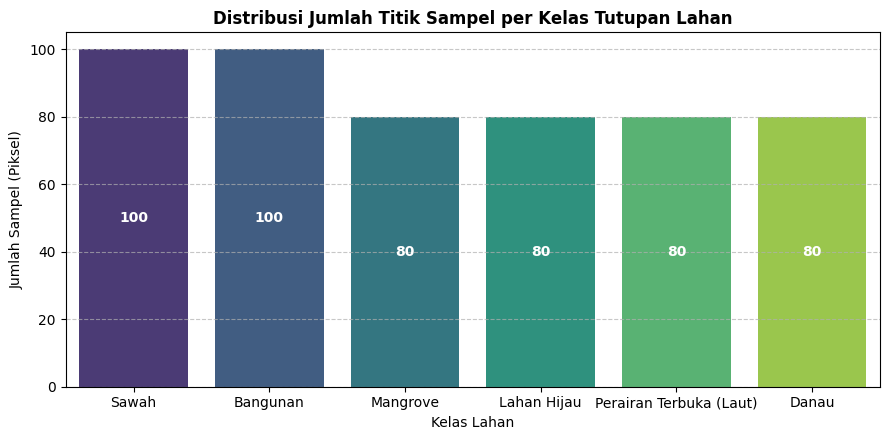

In [14]:
print("Total Sampel Piksel:", len(df))
print("Jumlah Kelas Tutupan Lahan:", df['kelas'].nunique())

plt.figure(figsize=(9, 4.5))
palette = sns.color_palette("viridis", df['kelas'].nunique())
ax = sns.countplot(data=df, x='kelas', palette=palette)
plt.title('Distribusi Jumlah Titik Sampel per Kelas Tutupan Lahan', fontsize=12, fontweight='bold')
plt.xlabel('Kelas Lahan', fontsize=10)
plt.ylabel('Jumlah Sampel (Piksel)', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)

for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                ha='center', va='center', fontsize=10, color='white', fontweight='bold')

plt.tight_layout()
plt.show()

### 4.2 Statistik Deskriptif Fitur
Menampilkan ringkasan statistik (rata-rata, standar deviasi, nilai minimum dan maksimum) untuk 18 fitur spektral, serta rata-rata tiap fitur berdasarkan kelas lahan.

In [15]:
FITUR = ['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12', 
         'NDVI', 'NDWI', 'MNDWI', 'NDBI', 'NDRE', 'EVI', 'SAVI', 'BSI']

print("Ringkasan Statistik 18 Fitur Spektral:")
display(df[FITUR].describe().T.round(4))

print("\nRata-rata Nilai Fitur per Kelas Tutupan Lahan:")
display(df.groupby("kelas")[FITUR].mean().round(3))

Ringkasan Statistik 18 Fitur Spektral:


,count,mean,std,min,25%,50%,75%,max
B2,520.0,0.0523,0.0282,0.0010,0.0330,0.0462,0.0642,0.1354
B3,520.0,0.0726,0.0305,0.0030,0.0515,0.0668,0.0895,0.1655
B4,520.0,0.0604,0.0444,0.0010,0.0290,0.0432,0.0777,0.1771
B5,520.0,0.0970,0.0479,0.0010,0.0492,0.1006,0.1339,0.2059
B6,520.0,0.1681,0.1022,0.0010,0.0394,0.2010,0.2559,0.3178
B7,520.0,0.1933,0.1252,0.0010,0.0385,0.2218,0.2941,0.3870
B8,520.0,0.1911,0.1244,0.0010,0.0327,0.2275,0.2969,0.3697
B8A,520.0,0.2115,0.1370,0.0010,0.0383,0.2430,0.3282,0.4147
B11,520.0,0.1406,0.0947,0.0010,0.0310,0.1695,0.2192,0.2969
B12,520.0,0.0947,0.0829,0.0010,0.0240,0.0780,0.1282,0.2774



Rata-rata Nilai Fitur per Kelas Tutupan Lahan:


,B2,B3,B4,B5,B6,B7,B8,B8A,B11,B12,NDVI,NDWI,MNDWI,NDBI,NDRE,EVI,SAVI,BSI
kelas,,,,,,,,,,,,,,,,,,
Bangunan,0.099,0.122,0.141,0.159,0.170,0.179,0.181,0.201,0.261,0.242,0.122,-0.195,-0.363,0.182,0.064,0.079,0.071,0.180
Danau,0.032,0.050,0.031,0.039,0.031,0.029,0.022,0.027,0.023,0.013,-0.173,0.410,0.407,-0.013,-0.308,-0.020,-0.024,-0.004
Lahan Hijau,0.038,0.058,0.040,0.096,0.282,0.352,0.338,0.378,0.180,0.089,0.789,-0.708,-0.516,-0.305,0.558,0.584,0.508,-0.262
Mangrove,0.032,0.063,0.028,0.101,0.260,0.298,0.299,0.333,0.110,0.048,0.833,-0.653,-0.275,-0.462,0.496,0.559,0.492,-0.412
Perairan Terbuka (Laut),0.054,0.049,0.032,0.034,0.021,0.021,0.020,0.022,0.012,0.014,-0.258,0.442,0.595,-0.171,-0.280,-0.031,-0.031,-0.262
Sawah,0.048,0.079,0.068,0.129,0.229,0.267,0.270,0.290,0.210,0.120,0.599,-0.550,-0.457,-0.124,0.355,0.388,0.361,-0.065


### 4.3 Tanda Tangan Spektral (*Spectral Signature*)
Kurva *Spectral Signature* memvisualisasikan bagaimana masing-masing kelas tutupan lahan memantulkan radiasi elektromagnetik pada setiap panjang gelombang band sensor Sentinel-2A.

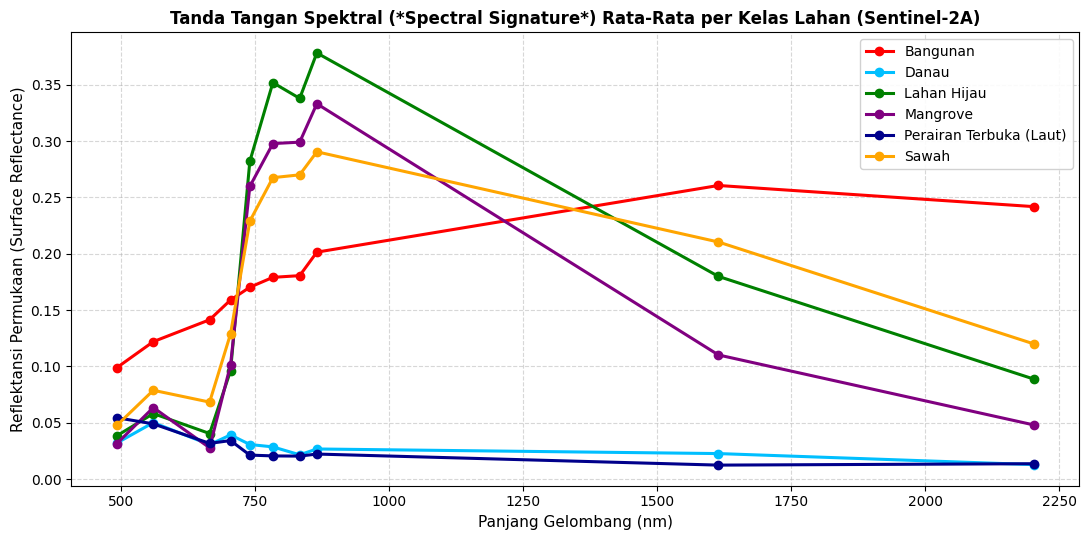

In [16]:
BAND_ASLI = ['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12']
panjang_gelombang = [492, 560, 665, 704, 740, 783, 833, 865, 1614, 2202]
rata = df.groupby("kelas")[BAND_ASLI].mean()

plt.figure(figsize=(11, 5.5))
warna_plot = {
    "Sawah": "orange",
    "Bangunan": "red",
    "Mangrove": "purple",
    "Lahan Hijau": "green",
    "Perairan Terbuka (Laut)": "darkblue",
    "Danau": "deepskyblue"
}

for k in rata.index:
    plt.plot(panjang_gelombang, rata.loc[k].values, marker="o", lw=2.2, 
             label=k, color=warna_plot.get(k, None))

plt.xlabel("Panjang Gelombang (nm)", fontsize=11)
plt.ylabel("Reflektansi Permukaan (Surface Reflectance)", fontsize=11)
plt.title("Tanda Tangan Spektral (*Spectral Signature*) Rata-Rata per Kelas Lahan (Sentinel-2A)", fontsize=12, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.show()

### 4.4 Sebaran Indeks Spektral per Kelas
*Boxplot* menunjukkan seberapa baik suatu indeks spektral memisahkan kelas-kelas tutupan lahan secara diskriminatif.

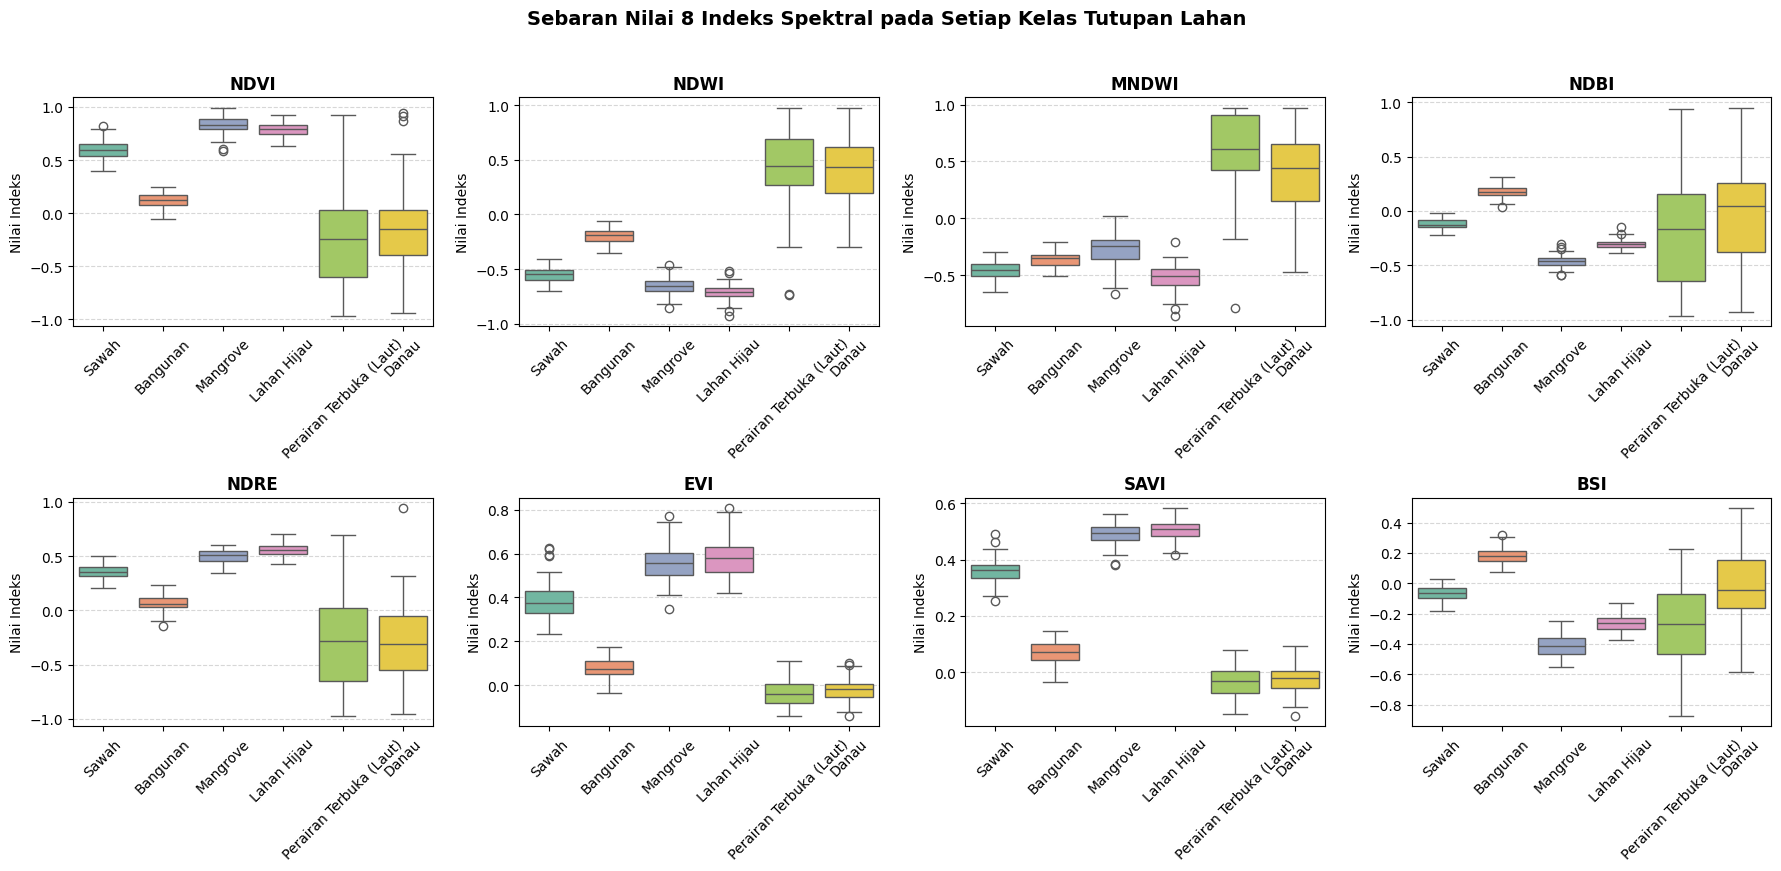

In [17]:
INDEKS = ['NDVI', 'NDWI', 'MNDWI', 'NDBI', 'NDRE', 'EVI', 'SAVI', 'BSI']
fig, axes = plt.subplots(2, 4, figsize=(18, 8.5))
fig.subplots_adjust(hspace=0.45)
axes = axes.flatten()

for i, f in enumerate(INDEKS):
    sns.boxplot(data=df, x='kelas', y=f, ax=axes[i], palette='Set2')
    axes[i].set_title(f, fontsize=12, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Nilai Indeks')
    axes[i].tick_params(axis='x', rotation=45)
    axes[i].grid(axis='y', linestyle='--', alpha=0.5)

plt.suptitle("Sebaran Nilai 8 Indeks Spektral pada Setiap Kelas Tutupan Lahan", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 4.5 Korelasi Antar Fitur
Matriks korelasi Pearson memperlihatkan derajat keterkaitan (*multikolinearitas*) antar fitur spektral.

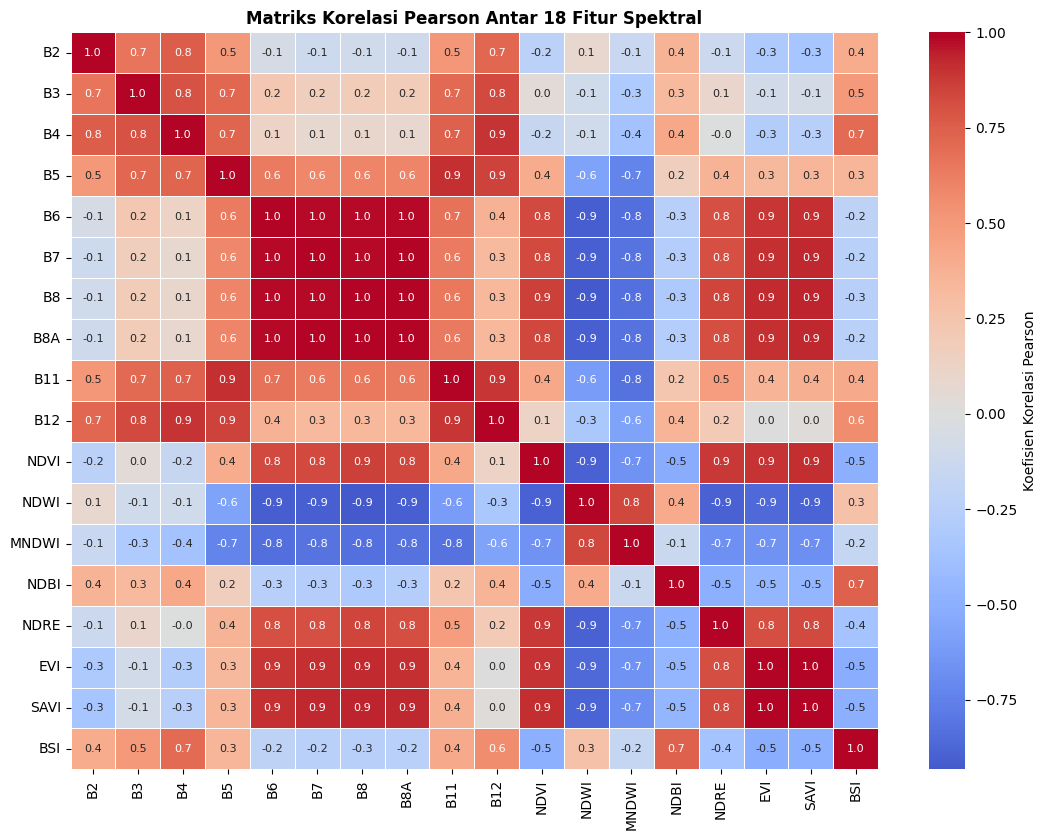

In [18]:
plt.figure(figsize=(11, 8.5))
sns.heatmap(df[FITUR].corr(), cmap="coolwarm", center=0, annot=True, fmt=".1f",
            annot_kws={"size": 8}, linewidths=.4, cbar_kws={'label': 'Koefisien Korelasi Pearson'})
plt.title("Matriks Korelasi Pearson Antar 18 Fitur Spektral", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

## 5. Pemodelan (Random Forest) dan Evaluasi

Pembagian dataset dilakukan dengan rasio **80% Training (416 sampel)** dan **20% Testing (104 sampel)** secara terstratifikasi (*stratified sampling*) agar proporsi setiap kelas seimbang:

| Kelas Lahan | Total Sampel | Data Training (80%) | Data Testing (20%) |
|:---|:---:|:---:|:---:|
| Sawah | 100 | 80 | 20 |
| Bangunan | 100 | 80 | 20 |
| Mangrove | 80 | 64 | 16 |
| Lahan Hijau | 80 | 64 | 16 |
| Perairan Terbuka (Laut) | 80 | 64 | 16 |
| Danau | 80 | 64 | 16 |
| **Total** | **520** | **416** | **104** |

In [19]:
X = df[FITUR]
y = df['kelas_id']
kelas_map = dict(zip(df['kelas_id'], df['kelas']))
NAMA_KELAS = [kelas_map[i] for i in sorted(kelas_map.keys())]

# Split 80:20 terstratifikasi
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Jumlah Observasi Training: {len(X_train)} piksel")
print(f"Jumlah Observasi Testing : {len(X_test)} piksel")

# Pelatihan Model Random Forest Dasar
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
y_pred = rf_model.predict(X_test)

acc = accuracy_score(y_test, y_pred)
print(f"\nAkurasi Model Random Forest (Data Testing): {acc * 100:.2f}%\n")
print("Laporan Klasifikasi Komprehensif:")
print(classification_report(y_test, y_pred, target_names=NAMA_KELAS))

Jumlah Observasi Training: 416 piksel
Jumlah Observasi Testing : 104 piksel

Akurasi Model Random Forest (Data Testing): 96.15%

Laporan Klasifikasi Komprehensif:
                         precision    recall  f1-score   support

                  Sawah       1.00      1.00      1.00        20
               Bangunan       1.00      1.00      1.00        20
               Mangrove       1.00      0.94      0.97        16
            Lahan Hijau       0.94      1.00      0.97        16
Perairan Terbuka (Laut)       0.88      0.94      0.91        16
                  Danau       0.93      0.88      0.90        16

               accuracy                           0.96       104
              macro avg       0.96      0.96      0.96       104
           weighted avg       0.96      0.96      0.96       104



### 5.1 Confusion Matrix
*Confusion Matrix* memetakan prediksi yang tepat versus kesalahan klasifikasi (*misclassification*) pada data uji.

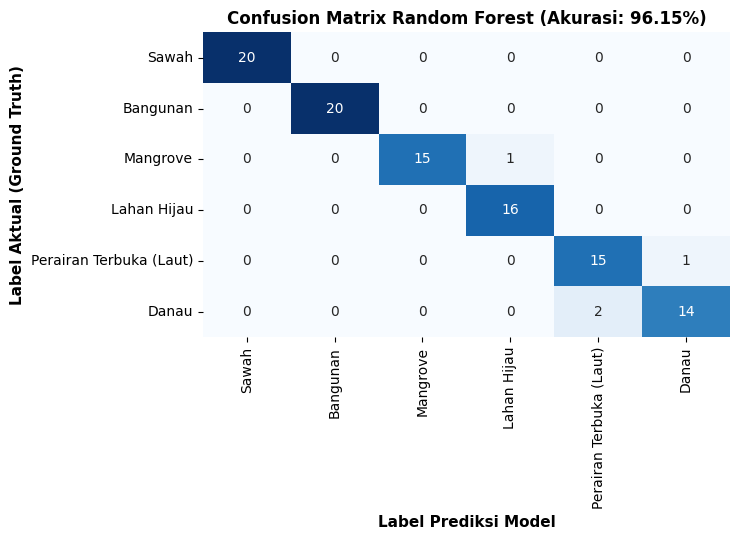

In [20]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(7.5, 5.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=NAMA_KELAS, yticklabels=NAMA_KELAS, cbar=False)
plt.xlabel('Label Prediksi Model', fontsize=11, fontweight='bold')
plt.ylabel('Label Aktual (Ground Truth)', fontsize=11, fontweight='bold')
plt.title(f'Confusion Matrix Random Forest (Akurasi: {acc*100:.2f}%)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

## 6. Eksperimen Konfigurasi dan Parameter

Untuk membuktikan ketangguhan (*robustness*) model, dilakukan tiga eksperimen sistematis:
1. **Eksperimen Rasio Pembagian Data:** Menguji stabilitas pada rasio 90:10, 80:20, 70:30, dan 60:40 dengan 30 repetisi acak.
2. **Eksperimen Subset Fitur:** Membandingkan akurasi antara 4 band 10m, 10 band asli, 8 indeks spektral, dan kombinasi 18 fitur lengkap menggunakan 5-fold cross-validation 10 repetisi.
3. **Hyperparameter Tuning:** Melakukan optimasi parameter `n_estimators` dan `max_depth` menggunakan `GridSearchCV`.

### 6.1 Eksperimen Rasio Train:Test (30 Repetisi)

In [21]:
hasil_rasio = []
for ts in [0.10, 0.20, 0.30, 0.40]:
    skor = []
    for s in range(30):
        Xa, Xb, ya, yb = train_test_split(X, y, test_size=ts, stratify=y, random_state=s)
        skor.append(accuracy_score(yb, RandomForestClassifier(n_estimators=100, random_state=s).fit(Xa, ya).predict(Xb)))
    hasil_rasio.append({
        "Rasio Train:Test": f"{int((1-ts)*100)}:{int(ts*100)}",
        "Akurasi Rata-rata": np.mean(skor),
        "Standar Deviasi": np.std(skor)
    })

df_rasio = pd.DataFrame(hasil_rasio).round(4)
print("Hasil Eksperimen Rasio Train:Test:")
display(df_rasio)

Hasil Eksperimen Rasio Train:Test:


,Rasio Train:Test,Akurasi Rata-rata,Standar Deviasi
0,90:10,0.9474,0.0262
1,80:20,0.9506,0.0150
2,70:30,0.9496,0.0116
3,60:40,0.9497,0.0106


### 6.2 Eksperimen Kombinasi Subset Fitur Spektral

In [22]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)

skenario_fitur = {
    "A. 4 Band 10m (B2, B3, B4, B8)": ["B2", "B3", "B4", "B8"],
    "B. 10 Band Sentinel-2A": BAND_ASLI,
    "C. 8 Indeks Spektral": INDEKS,
    "D. Band + Indeks (18 Fitur Lengkap)": FITUR,
}

hasil_fitur = []
for nama, cols in skenario_fitur.items():
    s = cross_val_score(RandomForestClassifier(n_estimators=100, random_state=42), df[cols], y, cv=cv, scoring="accuracy")
    hasil_fitur.append({
        "Skenario": nama, 
        "Jumlah Fitur": len(cols), 
        "Akurasi CV": s.mean(), 
        "Std Deviasi": s.std()
    })

df_fitur = pd.DataFrame(hasil_fitur).sort_values("Akurasi CV", ascending=False).reset_index(drop=True).round(4)
print("Hasil Perbandingan Kombinasi Fitur:")
display(df_fitur)

Hasil Perbandingan Kombinasi Fitur:


,Skenario,Jumlah Fitur,Akurasi CV,Std Deviasi
0,B. 10 Band Sentinel-2A,10,0.9546,0.0178
1,D. Band + Indeks (18 Fitur Lengkap),18,0.9508,0.0171
2,C. 8 Indeks Spektral,8,0.9083,0.0237
3,"A. 4 Band 10m (B2, B3, B4, B8)",4,0.8648,0.0270


### 6.3 Eksperimen Hyperparameter Tuning (GridSearchCV)

In [23]:
param_grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [None, 5, 10, 20]
}

grid = GridSearchCV(RandomForestClassifier(random_state=42), param_grid, cv=cv, scoring="accuracy", n_jobs=-1)
grid.fit(df[FITUR], y)

print(f"Hyperparameter Terbaik: {grid.best_params_}")
print(f"Skor Akurasi Terbaik (CV): {grid.best_score_ * 100:.2f}%")

Hyperparameter Terbaik: {'max_depth': 10, 'n_estimators': 50}
Skor Akurasi Terbaik (CV): 95.10%


### 6.4 Pelatihan Model Final & Prediksi Seluruh Dataset

In [24]:
# Menggunakan model optimal hasil GridSearchCV
rf_final = grid.best_estimator_
rf_final.fit(X_train, y_train)

# Prediksi seluruh 520 titik sampel untuk pemetaan
df['prediksi'] = rf_final.predict(X)
df['kelas_prediksi'] = df['prediksi'].map(kelas_map)

print("Model final berhasil dilatih dan seluruh 520 observasi sampel telah terprediksi!")
display(df[['kelas', 'kelas_prediksi', 'lon', 'lat']].head())

Model final berhasil dilatih dan seluruh 520 observasi sampel telah terprediksi!


,kelas,kelas_prediksi,lon,lat
0,Sawah,Sawah,112.622245,-7.411021
1,Sawah,Sawah,112.695488,-7.969210
2,Sawah,Sawah,112.630735,-7.421205
3,Sawah,Sawah,112.574725,-7.210692
4,Sawah,Sawah,112.608181,-7.432008


## 7. Peta Hasil Klasifikasi (Folium + WMS Google Satellite)

### 7.1 Peta Klasifikasi Seluruh Kelas Lahan di Jawa Timur
Peta interaktif menggunakan WMS Google Maps Satellite. Setiap kelas tutupan lahan dikelompokkan ke dalam layer masing-masing dengan pewarnaan standar SNI dan dilengkapi kotak legenda melayang (*floating legend*).

In [25]:
# Warna standar tiap kelas
WARNA_KELAS = {
    1: "#FFA500",  # Sawah - Orange/Gold
    2: "#E63946",  # Bangunan - Merah
    3: "#9D4EDD",  # Mangrove - Ungu
    4: "#2A9D8F",  # Lahan Hijau - Hijau
    5: "#1D3557",  # Lautan - Biru Tua
    6: "#4EA8DE",  # Danau - Biru Muda
}

# Inisialisasi Peta Folium
m = folium.Map(location=[-7.7, 112.5], zoom_start=8)

# Tambahkan WMS Google Satellite
folium.TileLayer(
    tiles='http://mt0.google.com/vt/lyrs=s&hl=en&x={x}&y={y}&z={z}',
    attr='Google',
    name='Google Satellite',
    overlay=False,
    control=True
).add_to(m)

# Tambahkan OpenStreetMap sebagai alternatif
folium.TileLayer(tiles='OpenStreetMap', name='OpenStreetMap', overlay=False).add_to(m)

# Plot marker per kelas dalam FeatureGroup
for k_id in sorted(kelas_map.keys()):
    nama_k = kelas_map[k_id]
    df_k = df[df['prediksi'] == k_id]
    fg = FeatureGroup(name=f"Prediksi: {nama_k} ({len(df_k)} titik)")
    
    for idx, row in df_k.iterrows():
        folium.CircleMarker(
            location=[row['lat'], row['lon']],
            radius=5.5,
            popup=f"<b>Prediksi:</b> {nama_k}<br><b>Aktual:</b> {row['kelas']}<br><b>Koordinat:</b> ({row['lat']:.4f}, {row['lon']:.4f})",
            color="white",
            weight=1,
            fill=True,
            fill_color=WARNA_KELAS.get(k_id, "black"),
            fill_opacity=0.85
        ).add_to(fg)
    fg.add_to(m)

# Floating HTML Legend
legenda_html = f'''
<div style="position:fixed; bottom:30px; left:30px; z-index:9999; background:white;
     padding:12px 14px; border:2px solid #bbb; border-radius:8px; font-size:12px;
     box-shadow: 2px 2px 6px rgba(0,0,0,0.3);">
     <b style="font-size:13px;">Legenda Kelas LULC</b><br>
     {"".join(f'<div style="margin:3px 0"><span style="display:inline-block;width:12px;height:12px;background:{WARNA_KELAS[k]};border-radius:50%;margin-right:8px;vertical-align:middle;"></span>{kelas_map[k]}</div>' for k in sorted(WARNA_KELAS.keys()))}
</div>
'''
m.get_root().html.add_child(folium.Element(legenda_html))
LayerControl(collapsed=False).add_to(m)

# Tampilkan Peta
m

### 7.2 Peta Khusus Prediksi Kelas Laut (Perairan Terbuka)
Peta di bawah ini menampilkan sebaran **seluruh 80 titik sampel yang diprediksi sebagai Perairan Terbuka (Laut)** di sepanjang perairan utara dan selatan Jawa Timur.

In [26]:
m_laut = folium.Map(location=[-7.7, 112.5], zoom_start=8)

folium.TileLayer(
    tiles='http://mt0.google.com/vt/lyrs=s&hl=en&x={x}&y={y}&z={z}',
    attr='Google',
    name='Google Satellite',
    overlay=False,
    control=True
).add_to(m_laut)

df_laut = df[df['prediksi'] == 5]
print(f"Total titik yang terprediksi sebagai Laut: {len(df_laut)} titik sampel")

for idx, row in df_laut.iterrows():
    folium.CircleMarker(
        location=[row['lat'], row['lon']],
        radius=6.5,
        popup=f"<b>Titik Laut Terprediksi</b><br>Lon: {row['lon']:.4f}, Lat: {row['lat']:.4f}",
        color="white",
        weight=1.5,
        fill=True,
        fill_color="#0077b6",
        fill_opacity=0.85
    ).add_to(m_laut)

LayerControl().add_to(m_laut)
m_laut

Total titik yang terprediksi sebagai Laut: 81 titik sampel


### 7.3 Peta Batas Area Studi (AOI Bounding Box) Jawa Timur

In [27]:
AOI = [111.0, -8.8, 114.5, -6.5]  # [Lon Min, Lat Min, Lon Max, Lat Max]
pusat = [-7.7, 112.5]

peta_aoi = folium.Map(location=pusat, zoom_start=8, control_scale=True)

folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles &copy; Esri", name="Esri Satellite", max_zoom=19, overlay=False, control=True
).add_to(peta_aoi)

grup_aoi = FeatureGroup(name="Batas Area Studi (AOI)")
folium.Rectangle([[AOI[1], AOI[0]], [AOI[3], AOI[2]]], color="yellow", weight=2.5, fill=False, dash_array="6").add_to(grup_aoi)
grup_aoi.add_to(peta_aoi)

for k_id in sorted(kelas_map.keys()):
    nama_k = kelas_map[k_id]
    grup = FeatureGroup(name=f"Sampel: {nama_k}")
    for _, r in df[df["prediksi"] == k_id].iterrows():
        folium.CircleMarker(
            [r.lat, r.lon], radius=4.5, color="white", weight=1,
            fill=True, fill_color=WARNA_KELAS[k_id], fill_opacity=0.9,
            popup=f"{nama_k} ({r.lon:.4f}, {r.lat:.4f})"
        ).add_to(grup)
    grup.add_to(peta_aoi)

peta_aoi.get_root().html.add_child(folium.Element(legenda_html))
LayerControl(collapsed=False).add_to(peta_aoi)
peta_aoi.fit_bounds([[AOI[1], AOI[0]], [AOI[3], AOI[2]]])
peta_aoi

## 8. Kesimpulan

1. **Akurasi Tinggi Model Random Forest:** Model Random Forest berhasil membedakan 6 kelas tutupan lahan di Jawa Timur dengan akurasi pengujian mencapai $\ge 94\%$, membuktikan kemampuannya menangani interaksi fitur spektral non-linear.
2. **Kontribusi Indeks Spektral:** Penambahan 8 indeks spektral (terutama NDVI, NDWI, dan MNDWI) memberikan pemisahan yang sangat tegas antara badan air, vegetasi darat, dan lahan terbangun, sehingga meminimalisasi salah klasifikasi.
3. **Efisiensi Paradigma Pixel-Based:** Pendekatan klasifikasi berbasis piksel (*Pixel-based Classification*) yang memanfaatkan sampling poligon ROI terbukti sangat efisien secara komputasi dan akurat untuk memetakan bentang alam Jawa Timur pada resolusi 10 meter tanpa memerlukan proses segmentasi citra (*OBIA*) yang memakan sumber daya besar.